# Phân loại cảm xúc review phim IMDb bằng LSTM

**Đề số 3** — Embedding + LSTM + Linear; mở rộng GRU, BiLSTM, GloVe.
**Nhóm 6 người:** Phạm Phương Thanh Thư, Nguyễn Khánh Toàn, Ngô Hồng Phúc, Phạm Thị Muội, Nguyễn Thái Bảo, Nguyễn Bảo Đại.

Notebook này **chỉ đọc kết quả** trong `experiments/` và `data/sample/`, không train lại. Kết quả mô hình do kernel Kaggle `lstm-pj-d1-d8` (Version 2) tạo ra, script ở `scripts/kaggle/`.

| Section | Nội dung | Mục báo cáo |
| :--- | :--- | :--- |
| 1 | Vấn đề và phạm vi | 1 |
| 2 | Dữ liệu và EDA | 2 |
| 3 | Baseline | 6 |
| 4 | Mô hình | 3 |
| 5 | Theo dõi quá trình huấn luyện | 3 |
| 6 | Đánh giá, so sánh với baseline | 6 |
| 7 | Phân tích lỗi | 7 |
| 8 | Giải thích mô hình | 7 |
| 9 | Demo | 5 |
| 10 | Giới hạn | 7 |

Cách cài đặt và chạy lại toàn bộ (mục 4 của báo cáo): xem `README.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
EXP, RES, PLOTS = ROOT / "experiments", ROOT / "experiments" / "results", ROOT / "experiments" / "plots"

# Tên thư mục thí nghiệm theo docs/MODELS.md
MODELS = {
    "lstm": "M1 LSTM",
    "gru": "M2 GRU",
    "bilstm": "M3 BiLSTM",
    "bilstm_glove_frozen": "M4a BiLSTM + GloVe (đóng băng)",
    "bilstm_glove_ft": "M4b BiLSTM + GloVe (fine-tune)",
    "bilstm_attention": "B BiLSTM + attention pooling",
}
SEEDS = [42, 123, 2025]
BEST_EXP = None  # None = tự chọn theo val acc (section 6); hoặc ghi tên, ví dụ "bilstm_glove_ft"

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def rel(p: Path) -> str:
    return p.relative_to(ROOT).as_posix()


def waiting(p: Path, who: str) -> None:
    display(Markdown(f"> ⏳ Chưa có `{rel(p)}` — chờ {who}."))


def read_json(p: Path):
    return json.loads(p.read_text(encoding="utf-8"))


def show_img(p: Path, who: str, width: int = 760) -> None:
    display(Image(filename=str(p), width=width)) if p.exists() else waiting(p, who)


def metrics_from_pred(df: pd.DataFrame) -> dict:
    # Metric từ file dự đoán (cột label, pred, prob theo hợp đồng ở docs/TASKS.md §4).
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    return {
        "n": len(df),
        "accuracy": accuracy_score(df["label"], df["pred"]),
        "macro_f1": f1_score(df["label"], df["pred"], average="macro"),
        "roc_auc": roc_auc_score(df["label"], df["prob"]),
    }


def pred_file(exp: str, split: str) -> Path:
    return RES / exp / f"predictions_{split}.csv"


def best_seed(exp: str) -> int:
    # seed có val acc cao nhất của một thí nghiệm
    accs = {s: read_json(m)["best_val_acc"] for s in SEEDS
            if (m := RES / exp / f"seed_{s}" / "metrics.json").exists()}
    return max(accs, key=accs.get)

print("ROOT =", ROOT)

ROOT = D:\MON_HOC\Nam-3-HK1\DOT-1\DL\LSTM_PJ


## 1. Vấn đề và phạm vi

- **Bài toán:** phân loại nhị phân cảm xúc review phim tiếng Anh: tích cực (1) hoặc tiêu cực (0).
- **Dữ liệu:** IMDb Large Movie Review Dataset (Maas et al., 2011): 25.000 review train và 25.000 review test, cân bằng nhãn. Review tiêu cực có điểm ≤ 4, tích cực có điểm ≥ 7; không có review trung tính (5–6).
- **Mô hình bắt buộc:** Embedding → LSTM → Linear. **Mở rộng:** GRU, BiLSTM, BiLSTM + GloVe (đóng băng / fine-tune), thử độ dài cắt `max_len` 200/400/600.
- **Baseline:** majority class và TF-IDF (1–2 gram) + Logistic Regression.
- **Thước đo chính:** accuracy (dữ liệu cân bằng); kèm macro-F1, ROC-AUC, confusion matrix. Chọn checkpoint và early stopping theo **val accuracy**.
- **Ngoài phạm vi:** review trung tính, đa ngôn ngữ, mô hình Transformer (chỉ trích số DistilBERT từ Lab 3 để tham chiếu).

## 2. Dữ liệu và EDA

### 2.1 Chia tập và làm sạch

- Val tách từ train gốc **theo phim** (StratifiedGroupKFold 10 fold, seed 42, fold 0), để một phim không nằm ở cả train và val. Dùng lại split của Lab 3 (`data/splits/train_val_split.json`).
- Loại review trùng nội dung (SHA-1 của văn bản đã làm sạch): trùng trong train/val giữ 1 bản; trùng giữa train/val và test bỏ bản ở train/val, **giữ nguyên test 25.000**.
- Bỏ review train/val của phim cũng có trong test (`tt0406816`).

In [2]:
st = read_json(RES / "data_prep" / "prepare_stats.json")
c = st["contract"]
assert c["hash_overlap_trainval_test"] == 0 and c["movie_overlap_train_val"] == 0 and c["movie_overlap_train_test"] == 0
for s in ["train", "val", "test"]:
    print(f"{s:5}: {st['inputs'][s]:>6,} → {st['outputs'][s]:>6,} | trùng trong split {st['removed_within_split'].get(s, 0):>3} | "
          f"trùng với test {st['removed_cross_split'].get(s, 0):>3} | phim trùng test {st['removed_movie_leak'].get(s, 0)}")
print(f"Tổng {c['n_rows']:,} review | trùng hash train/val–test = 0 | phim chung train–val = 0, train–test = 0")
print(f"Test giữ nguyên: {st['duplicates_in_test_kept']} bản trùng trong test, {st['test_reviews_also_in_train']} review trùng train gốc (section 6 báo thêm kết quả khi bỏ)")

train: 22,499 → 22,304 | trùng trong split  87 | trùng với test 106 | phim trùng test 2
val  :  2,501 →  2,473 | trùng trong split  11 | trùng với test  17 | phim trùng test 0
test : 25,000 → 25,000 | trùng trong split   0 | trùng với test   0 | phim trùng test 0
Tổng 49,777 review | trùng hash train/val–test = 0 | phim chung train–val = 0, train–test = 0
Test giữ nguyên: 201 bản trùng trong test, 123 review trùng train gốc (section 6 báo thêm kết quả khi bỏ)


### 2.2 Thống kê tổng quan

In [3]:
summary = pd.read_csv(RES / "eda" / "eda_summary.csv").set_index("split")
cols = {"n_reviews": "review", "n_movies": "phim", "len_median": "median (từ)", "len_p95": "P95",
        "len_pct_over_200": "% > 200", "len_pct_over_400": "% > 400", "pct_with_br": "% có <br />",
        "pct_with_negation": "% có phủ định"}
summary[list(cols)].rename(columns=cols).round(1)

,review,phim,median (từ),P95,% > 200,% > 400,% có <br />,% có phủ định
split,,,,,,,,
train,22304,3081,173.0,593.0,40.8,13.2,58.7,89.5
val,2473,343,173.0,589.2,41.6,12.6,58.7,89.4
test,25000,3581,170.0,576.0,39.8,12.2,58.1,89.1


1. Độ dài review (số từ):


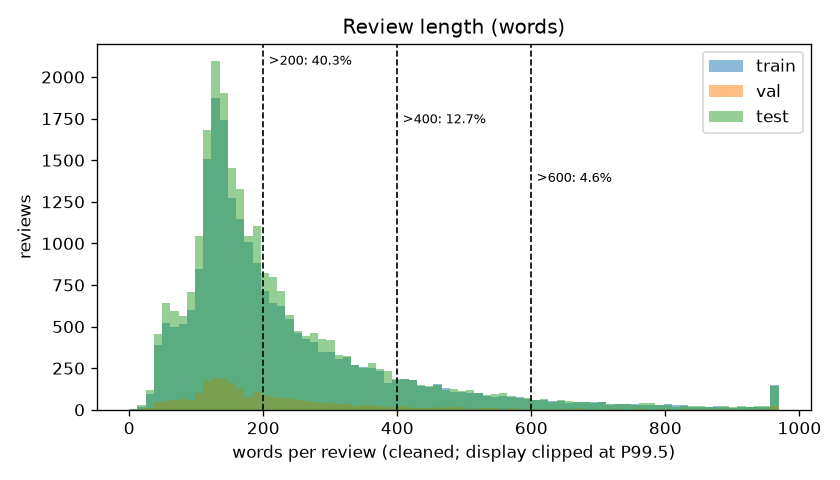

2. Độ dài theo nhãn:


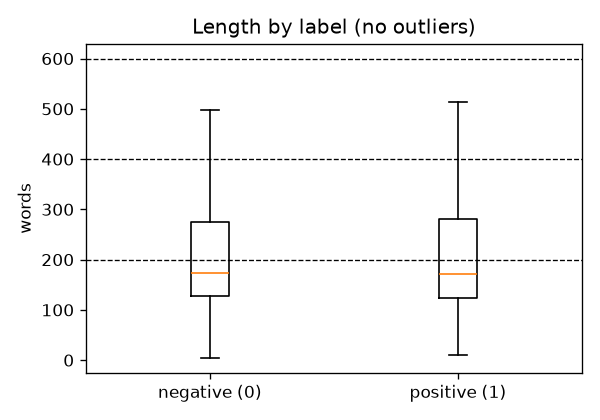

In [4]:
print("1. Độ dài review (số từ):")
show_img(PLOTS / "eda" / "eda_length_hist.png", "B2", width=720)
print("2. Độ dài theo nhãn:")
show_img(PLOTS / "eda" / "eda_length_by_label.png", "B2", width=480)

**Nhận xét độ dài:** khoảng 41% review train dài hơn 200 từ và khoảng 13% dài hơn 400 từ. Vì vậy chọn `max_len` ảnh hưởng tới việc mô hình có đọc được câu kết luận ở cuối review hay không. Thí nghiệm `max_len` 200/400/600 ở section 6 kiểm tra điều này.

### 2.3 Phủ định, từ phổ biến, điểm số

train, nhãn 0: 93.6% review có phủ định
train, nhãn 1: 85.4% review có phủ định
3. Từ phổ biến theo nhãn:


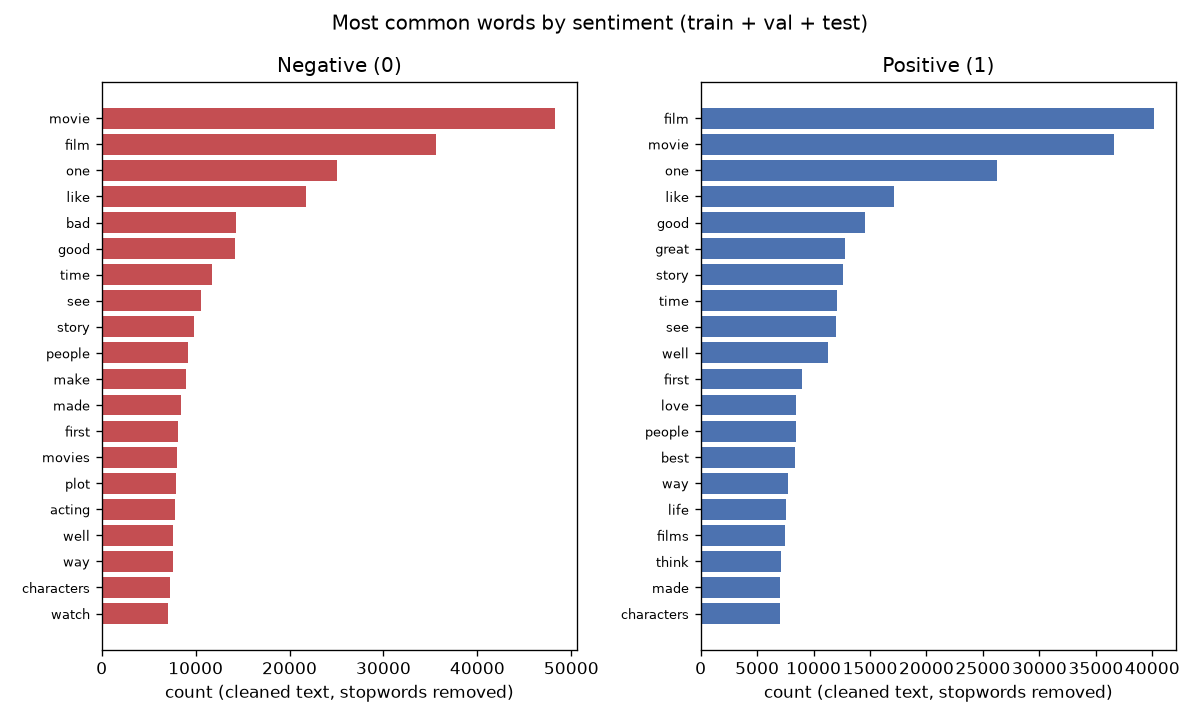

Số review theo điểm gốc (1–4: chê, 7–10: khen):


rating,1,2,3,4,7,8,9,10
test,5022,2302,2541,2635,2307,2850,2344,4999
train,4502,2034,2150,2410,2258,2690,2024,4236
val,526,221,239,252,233,310,223,469


In [5]:
neg = pd.read_csv(RES / "eda" / "eda_negation.csv")
for _, r in neg[neg["split"] == "train"].iterrows():
    print(f"train, nhãn {r['label']}: {r['pct_with_negation']:.1f}% review có phủ định")
print("3. Từ phổ biến theo nhãn:")
show_img(PLOTS / "eda" / "eda_top_words.png", "B2", width=720)
print("Số review theo điểm gốc (1–4: chê, 7–10: khen):")
pd.read_csv(RES / "eda" / "eda_ratings.csv").set_index("rating").T

- Phủ định xuất hiện ở khoảng 89% review, ở cả hai nhãn. Do đó không thể dựa riêng vào từ "not" để đoán nhãn. Mô hình tuần tự phải học được phủ định đổi nghĩa từ đi sau nó.
- Không có điểm 5–6, nên mô hình chưa từng thấy review trung tính (xem giới hạn, section 10).

### 2.4 Vấn đề chất lượng dữ liệu và mẫu dữ liệu

In [6]:
q = pd.read_csv(RES / "eda" / "eda_quality_issues.csv")
for _, r in q[q["scope"] == "split"].iterrows():
    print(f"{r['split']:5}: {r['check']}: {r['count']} ({r['detail']})")
sample = pd.read_csv(ROOT / "data" / "sample" / "sample_100.csv")
print(f"data/sample/sample_100.csv: {len(sample)} review test, theo loại: {sample['case_type'].value_counts().to_dict()}")

train: còn thẻ HTML khác <br /> trong text_clean: 7 (ví dụ <i>, </i> — clean_text chỉ bỏ <br />)
test : review trùng nội dung trong split (bản thừa): 201 (giữ 1 bản; test cố ý không xoá)
test : còn thẻ HTML khác <br /> trong text_clean: 3 (ví dụ <i>, </i> — clean_text chỉ bỏ <br />)
data/sample/sample_100.csv: 100 review test, theo loại: {'random': 30, 'long_review': 20, 'negation': 16, 'rating_4_negative': 12, 'rating_7_positive': 12, 'short_review': 10}


## 3. Baseline

- **M0a Majority:** luôn đoán nhãn nhiều nhất trong train.
- **M0b TF-IDF (1–2 gram, `min_df=2`) + Logistic Regression:** chọn `C` trên val trong lưới {0,01; 0,1; 1; 10; 30; 100}.

M0a Majority              : val acc 0.4994 | macro-F1 0.3331 | ROC-AUC 0.5000
M0b TF-IDF + LR (C = 10)  : val acc 0.8985 | macro-F1 0.8985 | ROC-AUC 0.9623


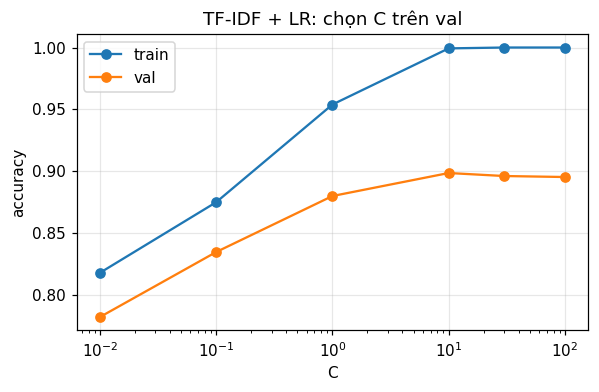

Confusion matrix M0b trên val: TN 1093, FP 145, FN 106, TP 1129


In [7]:
bm = read_json(RES / "baseline" / "metrics.json")
for name, v in [("M0a Majority", bm["M0a_majority"]["val"]), (f"M0b TF-IDF + LR (C = {bm['M0b_tfidf_lr']['selected_C']:g})", bm["M0b_tfidf_lr"]["val"])]:
    print(f"{name:26}: val acc {v['accuracy']:.4f} | macro-F1 {v['macro_f1']:.4f} | ROC-AUC {v['roc_auc']:.4f}")

grid = pd.read_csv(RES / "baseline" / "c_grid.csv")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(grid["C"], grid["train_accuracy"], "o-", label="train")
ax.plot(grid["C"], grid["val_accuracy"], "o-", label="val")
ax.set(xscale="log", xlabel="C", ylabel="accuracy", title="TF-IDF + LR: chọn C trên val")
ax.legend(); plt.show()
cm = bm["M0b_tfidf_lr"]["val"]["confusion_matrix"]["matrix"]
print(f"Confusion matrix M0b trên val: TN {cm[0][0]}, FP {cm[0][1]}, FN {cm[1][0]}, TP {cm[1][1]}")

Baseline TF-IDF + LR đạt **val acc ≈ 0,899**, nhưng train acc ≈ 0,999 nên overfit khoảng 10 điểm. Đây là mốc mô hình LSTM phải vượt.

## 4. Mô hình

Cùng một khung `SentimentRNN`: **Embedding → RNN → lấy trạng thái ẩn cuối → Dropout → Linear → 1 logit** (BCEWithLogitsLoss). Chỉ thay loại RNN, số chiều và embedding:

| Mã | Mô hình | Embedding | RNN |
| :--- | :--- | :--- | :--- |
| M1 | LSTM (bắt buộc) | học từ đầu, 100d | LSTM 1 chiều, 128 |
| M2 | GRU | học từ đầu, 100d | GRU 1 chiều, 128 |
| M3 | BiLSTM | học từ đầu, 100d | LSTM 2 chiều, 128 × 2 |
| M4a | BiLSTM + GloVe | GloVe 100d, đóng băng | LSTM 2 chiều, 128 × 2 |
| M4b | BiLSTM + GloVe | GloVe 100d, fine-tune | LSTM 2 chiều, 128 × 2 |
| E1 | BiLSTM + attention | học từ đầu, 100d | LSTM 2 chiều, 128 × 2; attention pooling thay trạng thái cuối |

Mỗi cấu hình chạy 3 seed (42, 123, 2025), báo mean ± std. Chi tiết siêu tham số: `docs/MODELS.md`, `configs/`.

In [8]:
rows = {}
for exp, name in MODELS.items():
    s = read_json(RES / exp / "summary.json")
    rows[name] = {"tham số": f"{s['parameters']['total']:,}", "train được": f"{s['parameters']['trainable']:,}",
                  "val acc (3 seed)": s["best_val_acc"]["formatted"], "train acc tại best": s["train_acc_at_best"]["formatted"],
                  "phút train / seed": round(s["total_train_seconds"]["mean"] / 60, 1)}
pd.DataFrame(rows).T

,tham số,train được,val acc (3 seed),train acc tại best,phút train / seed
M1 LSTM,"2,617,889","2,617,889",86.09 ± 0.33%,94.19 ± 3.02%,2.7
M2 GRU,"2,588,449","2,588,449",88.27 ± 0.45%,96.21 ± 0.79%,2.0
M3 BiLSTM,"2,735,777","2,735,777",86.29 ± 0.93%,94.31 ± 1.31%,3.2
M4a BiLSTM + GloVe (đóng băng),"2,735,777","235,777",87.76 ± 0.31%,92.12 ± 1.93%,3.8
M4b BiLSTM + GloVe (fine-tune),"2,735,777","2,735,777",86.70 ± 0.65%,90.56 ± 3.16%,1.8
B BiLSTM + attention pooling,"2,768,802","2,768,802",88.26 ± 0.58%,92.79 ± 1.40%,2.9


## 5. Theo dõi quá trình huấn luyện

Mỗi epoch ghi `history.csv`: `epoch, train_loss, train_acc, val_loss, val_acc, val_f1, grad_norm_mean, lr, epoch_seconds`. Với mỗi cấu hình, chồng 3 seed lên cùng hình:

- **Loss và accuracy train/val:** đánh dấu epoch tốt nhất theo val acc.
- **Khoảng cách train acc − val acc:** cho thấy mức overfit.
- **Grad norm:** phát hiện nổ gradient.

1. Mô hình bắt buộc (LSTM) và mô hình được chọn (GRU), 3 seed:


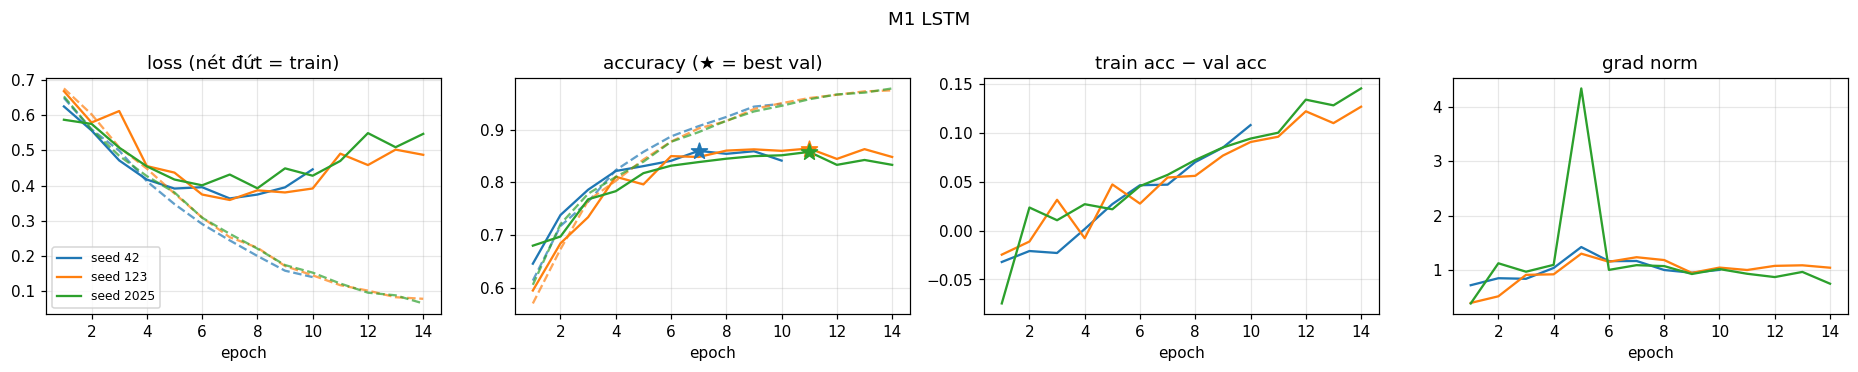

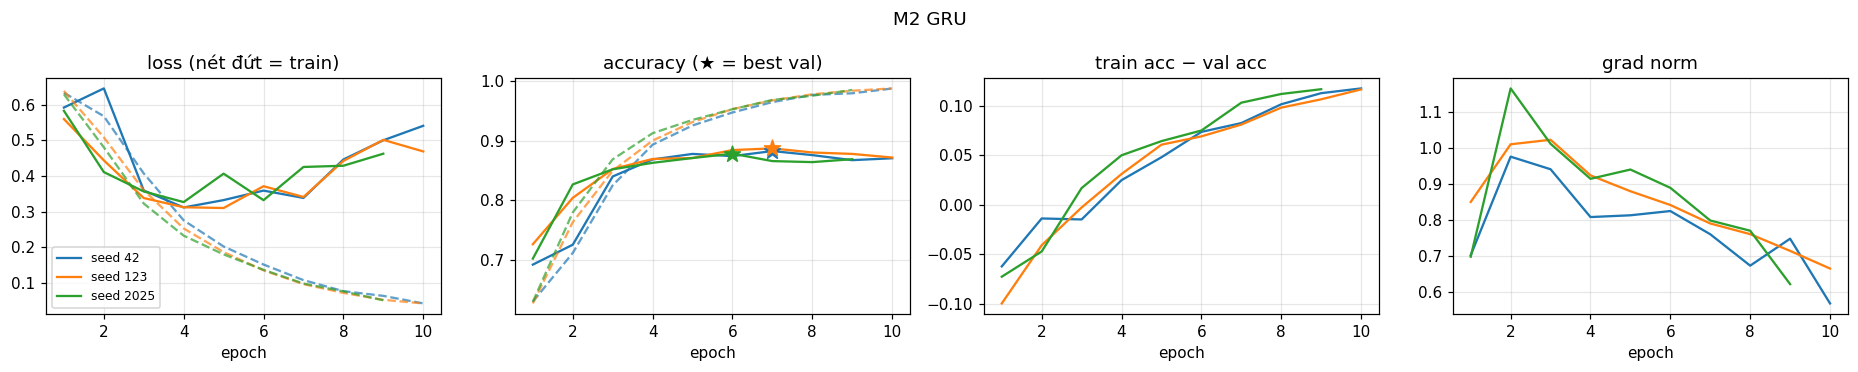

2. Tóm tắt 6 mô hình × 3 seed (hình đủ 6 mô hình: experiments/plots/training/):


,epoch tốt nhất,epoch dừng,train − val tại best (điểm),val loss min sớm hơn,grad norm max
M1 LSTM,7–11,10–14,4.7–10.0,2/3,4.34
M2 GRU,6–7,9–10,7.5–8.2,3/3,1.17
M3 BiLSTM,8–9,11–12,7.2–8.5,3/3,2.23
M4a BiLSTM + GloVe (đóng băng),9–14,12–17,2.4–5.6,2/3,2.86
M4b BiLSTM + GloVe (fine-tune),3–4,6–7,2.3–6.9,1/3,4.74
B BiLSTM + attention pooling,3–4,6–7,3.6–5.3,1/3,0.61


In [9]:
def find_history(exp, seed):
    # results/ được commit; runs/ nằm trong .gitignore nên chỉ có trên máy đã train
    for p in [RES / exp / f"seed_{seed}" / "history.csv", EXP / "runs" / exp / f"seed_{seed}" / "history.csv"]:
        if p.exists():
            return pd.read_csv(p)
    return None


def plot_curves(exp, name):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
    for s in SEEDS:
        h = find_history(exp, s)
        best = h.loc[h["val_acc"].idxmax()]
        l, = axes[0].plot(h["epoch"], h["train_loss"], "--", alpha=0.7)
        axes[0].plot(h["epoch"], h["val_loss"], "-", color=l.get_color(), label=f"seed {s}")
        axes[1].plot(h["epoch"], h["train_acc"], "--", color=l.get_color(), alpha=0.7)
        axes[1].plot(h["epoch"], h["val_acc"], "-", color=l.get_color())
        axes[1].scatter([best["epoch"]], [best["val_acc"]], color=l.get_color(), marker="*", s=120, zorder=3)
        axes[2].plot(h["epoch"], h["train_acc"] - h["val_acc"], color=l.get_color())
        axes[3].plot(h["epoch"], h["grad_norm_mean"], color=l.get_color())
    for ax, t in zip(axes, ["loss (nét đứt = train)", "accuracy (★ = best val)", "train acc − val acc", "grad norm"]):
        ax.set(title=t, xlabel="epoch")
    axes[0].legend(fontsize=8)
    fig.suptitle(name); plt.tight_layout(); plt.show()


def run_stats(exp):
    r = []
    for s in SEEDS:
        h = find_history(exp, s)
        b = h.loc[h["val_acc"].idxmax()]
        r.append({"best": int(b["epoch"]), "stop": int(h["epoch"].max()), "gap": b["train_acc"] - b["val_acc"],
                  "loss_first": int(h.loc[h["val_loss"].idxmin(), "epoch"]) < int(b["epoch"]), "grad": h["grad_norm_mean"].max()})
    r = pd.DataFrame(r)
    rng = lambda c: f"{r[c].min()}–{r[c].max()}"
    return {"epoch tốt nhất": rng("best"), "epoch dừng": rng("stop"),
            "train − val tại best (điểm)": f"{r['gap'].min() * 100:.1f}–{r['gap'].max() * 100:.1f}",
            "val loss min sớm hơn": f"{int(r['loss_first'].sum())}/3", "grad norm max": round(r["grad"].max(), 2)}


print("1. Mô hình bắt buộc (LSTM) và mô hình được chọn (GRU), 3 seed:")
for exp in ["lstm", "gru"]:
    plot_curves(exp, MODELS[exp])
stats = pd.DataFrame({name: run_stats(exp) for exp, name in MODELS.items()}).T
assert (stats["epoch dừng"].str.split("–").str[1].astype(int) < 20).all(), "có lần chạy chạm trần 20 epoch"
print("2. Tóm tắt 6 mô hình × 3 seed (hình đủ 6 mô hình: experiments/plots/training/):")
stats

**Cách đọc:**
- Nếu `min_val_loss_epoch` sớm hơn `best_epoch` thì val loss đã tăng trong khi val acc vẫn tăng. Mô hình tự tin quá mức trên một số mẫu, nhưng số mẫu đúng vẫn tăng. Đây là lý do nhóm chọn checkpoint theo val acc thay vì val loss.
- Khoảng cách train − val tăng dần nghĩa là overfit.

**Nhận xét (6 mô hình × 3 seed, `max_len` = 400):**
- **Early stopping hoạt động đúng:** cả 18 lần chạy đều dừng trước trần 20 epoch (dừng ở epoch 6–17), checkpoint giữ ở epoch có val acc cao nhất.
- **Overfit nhanh:** tại epoch tốt nhất, train acc cao hơn val acc 2–10 điểm; sau đó val loss tăng rõ. Ở 12/18 lần chạy, val loss thấp nhất **sớm hơn** epoch có val acc cao nhất — đúng hiện tượng mô tả ở trên, xác nhận lựa chọn theo val acc.
- **Tốc độ hội tụ khác nhau theo kiến trúc:** attention và GloVe fine-tune tốt nhất ở epoch 3–4; GRU 6–7; LSTM 7–11 (không đều giữa các seed); GloVe đóng băng chậm nhất, 9–14, vì chỉ train 8,6% tham số.
- **Không có nổ gradient:** grad norm trung bình mỗi epoch lớn nhất là 4,74, dưới ngưỡng clipping 5,0; attention ổn định nhất (≤ 0,61).
- **GloVe đóng băng ít overfit nhất** (khoảng cách train − val 2–6 điểm), nhưng đổi lại hội tụ chậm.

## 6. Đánh giá và so sánh với baseline

Quy trình: chọn cấu hình và checkpoint **chỉ dựa trên val**, sau đó chạy test **một lần**. Bảng so sánh và kiểm định McNemar do Đại tạo (`src/evaluate.py`). Notebook đọc lại các file đó (repo không lưu `predictions_*.csv` vì mỗi file khoảng 33 MB).

In [10]:
test = pd.read_csv(RES / "comparison_test.csv").set_index("model")
val = pd.read_csv(RES / "comparison_val.csv").set_index("model")
tbl = pd.DataFrame({"val acc": val["accuracy"], "test acc": test["accuracy"], "test macro-F1": test["macro_f1"],
                    "test ROC-AUC": test["roc_auc"]})
tbl.loc[test.index.difference(val.index), "val acc"] = "—"
tbl.reindex(test.index).fillna("—")

,val acc,test acc,test macro-F1,test ROC-AUC
model,,,,
M0a_majority,49.94%,50.00%,0.3333,0.5000
M0b_tfidf_lr (C=10),89.85%,89.94%,0.8994,0.9630
bilstm,86.29 ± 0.93%,86.53 ± 0.45%,0.8652 ± 0.0045,0.9369
bilstm_attention,88.26 ± 0.58%,88.28 ± 0.16%,0.8828 ± 0.0016,0.9527
bilstm_glove_frozen,87.76 ± 0.31%,87.87 ± 0.29%,0.8787 ± 0.0028,0.9505
bilstm_glove_ft,86.70 ± 0.65%,86.72 ± 0.34%,0.8670 ± 0.0035,0.9441
gru,88.27 ± 0.45%,88.16 ± 0.18%,0.8816 ± 0.0018,0.9499
lstm,86.09 ± 0.33%,86.48 ± 0.32%,0.8648 ± 0.0032,0.9321
"DistilBERT (tham chiếu Lab 3, không train lại)",—,93.00–93.40%,—,—


Tham chiếu ngoài (không chạy lại): **DistilBERT fine-tune, Lab 3: test acc 0,930–0,934**. Mô hình Transformer có tiền huấn luyện được đưa vào để thấy trần hiệu năng; nó không phải đối thủ cùng hạng với LSTM.

In [11]:
# repo không lưu predictions_*.csv (33 MB/file) → chọn theo mean val acc 3 seed trong summary.json
cands = {k: read_json(RES / k / "summary.json")["best_val_acc"]["mean"] for k in MODELS}
if BEST_EXP is None:
    BEST_EXP = max(cands, key=cands.get)
for k, v in sorted(cands.items(), key=lambda x: -x[1]):
    print(f"{MODELS[k]:32} val acc {v:.4f}{'  ← chọn' if k == BEST_EXP else ''}")

M2 GRU                           val acc 0.8827  ← chọn
B BiLSTM + attention pooling     val acc 0.8826
M4a BiLSTM + GloVe (đóng băng)   val acc 0.8776
M4b BiLSTM + GloVe (fine-tune)   val acc 0.8670
M3 BiLSTM                        val acc 0.8629
M1 LSTM                          val acc 0.8609


M2 GRU, seed 123 (val acc cao nhất trong 3 seed), test 25,000 review:
  accuracy 0.8821 | macro-F1 0.8821 | ROC-AUC 0.9487
  bỏ 123 review trùng train: accuracy 0.8821
  chê → khen (FP) 1,431 | khen → chê (FN) 1,516
3. Confusion matrix và ROC trên test:


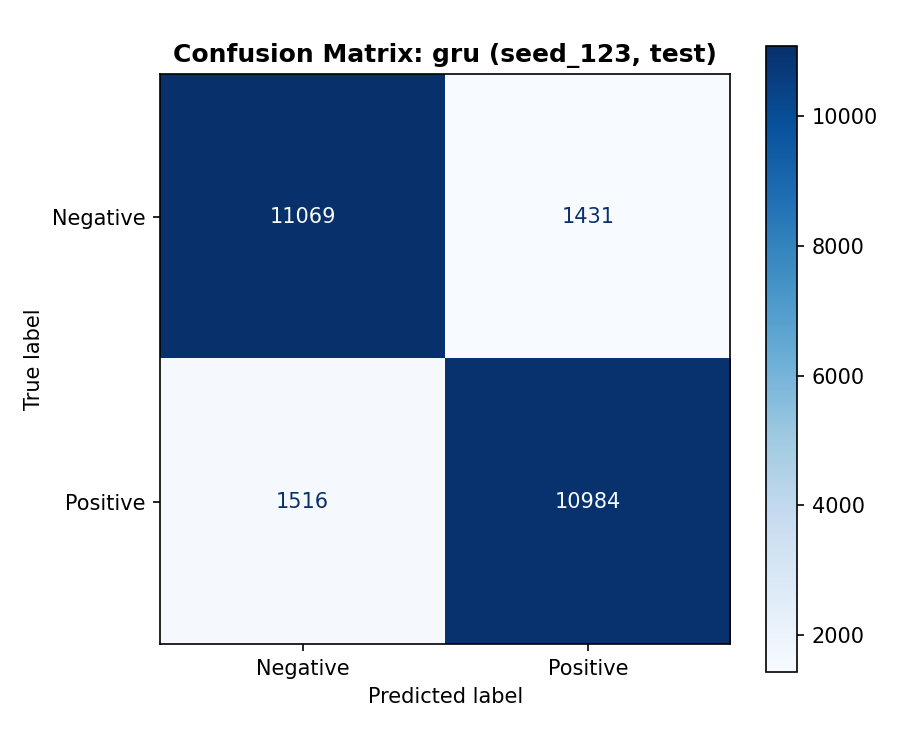

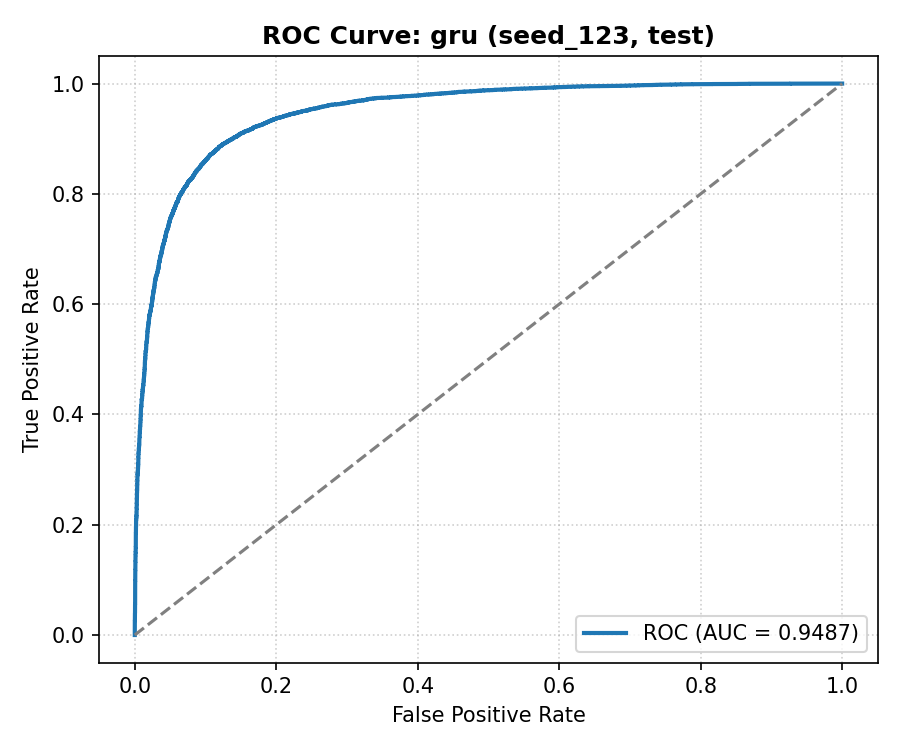

In [12]:
s = best_seed(BEST_EXP)
tm = read_json(RES / BEST_EXP / f"seed_{s}" / "test_metrics.json")
m, md, cm = tm["metrics"], tm["metrics_without_train_dups"], tm["metrics"]["confusion_matrix"]
print(f"{MODELS[BEST_EXP]}, seed {s} (val acc cao nhất trong 3 seed), test {cm['total']:,} review:")
print(f"  accuracy {m['accuracy']:.4f} | macro-F1 {m['macro_f1']:.4f} | ROC-AUC {m['roc_auc']:.4f}")
print(f"  bỏ {tm['n_removed_train_dups']} review trùng train: accuracy {md['accuracy']:.4f}")
print(f"  chê → khen (FP) {cm['fp']:,} | khen → chê (FN) {cm['fn']:,}")
print("3. Confusion matrix và ROC trên test:")
show_img(PLOTS / "eval" / f"{BEST_EXP}_seed_{s}_test_cm.png", "D8", width=420)
show_img(PLOTS / "eval" / f"{BEST_EXP}_seed_{s}_test_roc.png", "D8", width=420)

In [13]:
mc = read_json(RES / "mcnemar.json")
t = mc["contingency_table"]
print(f"McNemar {mc['model_a']} vs {mc['model_b']} trên {t['total']:,} review test:")
print(f"  {mc['model_b']} đúng, {mc['model_a']} sai: {t['a_wrong_b_correct']:,} | {mc['model_a']} đúng, {mc['model_b']} sai: {t['a_correct_b_wrong']:,}")
print(f"  exact p = {mc['exact_p_value']:.1e} → mô hình tốt hơn: {mc['better_model']}")

McNemar gru vs M0b_TFIDF_LR trên 25,000 review test:
  M0b_TFIDF_LR đúng, gru sai: 1,519 | gru đúng, M0b_TFIDF_LR sai: 1,086
  exact p = 2.2e-17 → mô hình tốt hơn: M0b_TFIDF_LR


### Chốt `max_len` (pilot D5) và mở rộng A (D7)

Theo plan, `max_len` được chốt ở bước pilot D5 **trước** 18 lần chạy chính: LSTM M1, seed 42, so sánh trên val. Quy tắc ghi trước khi chạy: lấy val acc cao nhất; nếu chênh < 0,5 điểm thì lấy giá trị nhỏ hơn (chạy nhanh hơn). Cả 6 mô hình chính dùng giá trị đã chốt, cắt đuôi (`post`). D7 thử thêm cách cắt và các mức khác trên mô hình tốt nhất (1 seed).

In [14]:
pilot, dd = pd.read_csv(RES / "pilot_maxlen.csv"), read_json(RES / "pilot_decision.json")
assert dd["epoch_cap_ok"]
print("Pilot D5 (LSTM, seed 42, val):")
for _, r in pilot.iterrows():
    print(f"  max_len {int(r['max_len']):>3}: val acc {r['best_val_acc']:.4f} (best epoch {int(r['best_epoch'])})")
print(f"→ chốt max_len = {dd['chosen_max_len']} · quy tắc: {dd['rule']}")
ml = pd.read_csv(RES / "maxlen_comparison.csv")
print("Mở rộng A (D7, GRU, seed 42, val):")
ml.set_index("variant")[["max_len", "truncation", "pct_train_truncated", "val_accuracy", "val_roc_auc"]].rename(
    columns={"pct_train_truncated": "% train bị cắt", "val_accuracy": "val acc", "val_roc_auc": "val ROC-AUC"})

Pilot D5 (LSTM, seed 42, val):
  max_len 200: val acc 0.8302 (best epoch 13)
  max_len 250: val acc 0.8374 (best epoch 10)
  max_len 400: val acc 0.8601 (best epoch 7)
  max_len 600: val acc 0.8629 (best epoch 9)
→ chốt max_len = 400 · quy tắc: val acc cao nhất; chênh < 0.5 điểm thì chọn max_len nhỏ hơn
Mở rộng A (D7, GRU, seed 42, val):


,max_len,truncation,% train bị cắt,val acc,val ROC-AUC
variant,,,,,
maxlen_200_post,200,post,52.32,0.8471,0.9263
maxlen_600_post,600,post,7.88,0.8852,0.9482
maxlen_400_pre,400,pre,18.73,0.8864,0.9490
maxlen_400_head_tail,400,head_tail,18.73,0.8856,0.9510


**Nhận xét** (chi tiết từng thí nghiệm: `docs/experiments/EXP_02`–`EXP_07`):
- **Baseline vẫn thắng.** TF-IDF + LR 89,94% test, hơn GRU (mô hình chọn theo val) 1,8 điểm. McNemar: baseline đúng riêng 1.519 review, GRU đúng riêng 1.086, p < 0,001 → khác biệt có ý nghĩa thống kê. TF-IDF đọc toàn bộ review và tận dụng tốt các từ khoá cảm xúc; RNN chỉ thấy 400 token và phải tự học nghĩa từ với 22 nghìn review.
- **GRU hơn LSTM khoảng 2 điểm** (88,16% so với 86,48%) dù ít tham số hơn và train nhanh hơn 25%; ổn định hơn qua 3 seed.
- **BiLSTM không giúp:** +0,05 điểm test so với LSTM, nhỏ hơn độ lệch giữa các seed.
- **GloVe đóng băng +1,3 điểm** so với embedding ngẫu nhiên và ổn định nhất; **fine-tune GloVe mất gần hết lợi ích** vì overfit sau 3–4 epoch.
- **Attention pooling +1,75 điểm** so với hidden cuối, ROC-AUC cao nhất (0,9527) — ngang GRU. Nhóm giữ GRU vì quy tắc chọn theo mean val acc (88,27% so với 88,26%), không đổi sau khi xem test.
- **`max_len` ảnh hưởng lớn nhất:** 250 → 400 làm mọi mô hình tăng 1,6–2,2 điểm test; 600 gần như không thêm; cách cắt (`post` / `pre` / `head_tail`) chênh trong mức nhiễu.
- **Mục tiêu đăng ký:** M1 (LSTM ≥ 85%) và M2 (mô hình tốt nhất ≥ 88%, macro-F1 ≥ 0,88) đều đạt.

## 7. Phân tích lỗi

Phân tích trên test chỉ để **mô tả**, không quay lại tinh chỉnh mô hình. Có 7 nhóm tình huống (`docs/phases/EVAL.md`):

1. Độ dài: < 100, 100–300, 300–600, > 600 từ (cắt ngắn có làm mất câu kết luận không).
2. Phủ định.
3. Khen chê lẫn lộn, đổi giọng ở cuối.
4. Mỉa mai, châm biếm.
5. Điểm sát ngưỡng (4, 7) so với điểm cực trị (1, 10).
6. Nhiều từ OOV hoặc từ hiếm.
7. 30 câu tự viết (`data/sample/handwritten_30.csv`).

Bảng đầy đủ và ví dụ sai kèm giải thích do `src/eval/error_analysis.py` (T2) tạo, lưu ở `experiments/results/error_analysis/`.

In [15]:
EA = RES / "error_analysis"
s = read_json(EA / "summary.json")
print(f"{s['model'].upper()} seed {s['seed']}: sai {s['n_errors']:,} / {s['n_test']:,} review test "
      f"(chê → khen {s['false_positive']:,}, khen → chê {s['false_negative']:,})")
g = pd.read_csv(EA / "by_group.csv")
g = g[g["group"] != "sarcasm_candidate"]
g.assign(**{"GRU": (g["acc_model"] * 100).round(1), "baseline": (g["acc_baseline"] * 100).round(1),
            "chênh": (g["delta_model_minus_baseline"] * 100).round(1)}).set_index(["group", "subgroup"])[["n", "GRU", "baseline", "chênh"]]

GRU seed 123: sai 2,947 / 25,000 review test (chê → khen 1,431, khen → chê 1,516)


n   GRU  baseline  chênh
group        subgroup                                       
length       <100                2290  88.9      90.8   -1.9
             100–300            15529  89.3      90.1   -0.8
             300–600             5342  87.4      89.1   -1.7
             >600                1839  80.8      89.9   -9.1
truncated    False              20600  89.3      90.1   -0.8
             True                4400  83.2      89.2   -6.1
negation     0–2                11207  89.3      90.5   -1.2
             3–5                 8440  88.3      89.4   -1.1
             6+                  5353  85.8      89.6   -3.8
contrast_end False              13205  89.6      91.1   -1.6
             True               11795  86.7      88.6   -1.9
rating       cực trị (1, 10)    10021  92.4      94.4   -2.0
             giữa (2, 3, 8, 9)  10037  88.6      90.7   -2.1
             sát ngưỡng (4, 7)   4942  78.9      79.3   -0.4
oov          <1%                 9037  89.5      91.6   -2.0
             1–3%               11658  88.0      89.6   -1.5
             >3%                 4305  85.9      87.6   -1.6

In [16]:
m50 = pd.read_csv(EA / "manual_label_50.csv")
print("50 lỗi gán tay (lấy ngẫu nhiên, seed 42, trong 1.591 lỗi có từ đổi ý cuối bài hoặc từ mỉa mai; quy tắc: docs/phases/EVAL.md):")
for k, v in (m50["manual_type"].value_counts(normalize=True) * 100).round().items():
    print(f"  {k:22} {v:.0f}%")
ex = pd.read_csv(EA / "error_examples.csv")
print(f"Ví dụ sai kèm giải thích: {len(ex)} dòng = {ex['case'].nunique()} nhóm × 10 (error_examples.csv). Ba ví dụ:")
ex.groupby("case").head(1).head(3)[["case", "uid", "label", "prob", "explanation"]]

50 lỗi gán tay (lấy ngẫu nhiên, seed 42, trong 1.591 lỗi có từ đổi ý cuối bài hoặc từ mỉa mai; quy tắc: docs/phases/EVAL.md):
  mixed                  28%
  negation               18%
  other                  16%
  target_shift           12%
  sarcasm                12%
  truncated_conclusion   8%
  label_noise            6%
Ví dụ sai kèm giải thích: 70 dòng = 7 nhóm × 10 (error_examples.csv). Ba ví dụ:


,case,uid,label,prob,explanation
0,length=>600,test_neg_8319,0,0.998383,"[cắt mất kết luận] Kết luận chê ('rotten by the end', 1.5/4) nằm cuối review 871 token, bị cắt ở 400; phần đầu khen ..."
10,truncated=True,test_neg_6999,0,0.998159,"[nhiễu nhãn] Bài chỉ khen hoặc trung tính ('a hoot', 'a great runaway horse scene') mà chấm 4."
20,negation=6+,test_neg_90,0,0.999037,"[phủ định] 'not given a 1 (awful) vote' rồi khen diễn xuất 'superb', 'lovely' — mô hình bám lời khen diễn viên, bỏ q..."


### 7.1 Accuracy theo nhóm và lỗi tự tin nhất

4. Accuracy theo nhóm, GRU so với baseline (đủ 25.000 review test):


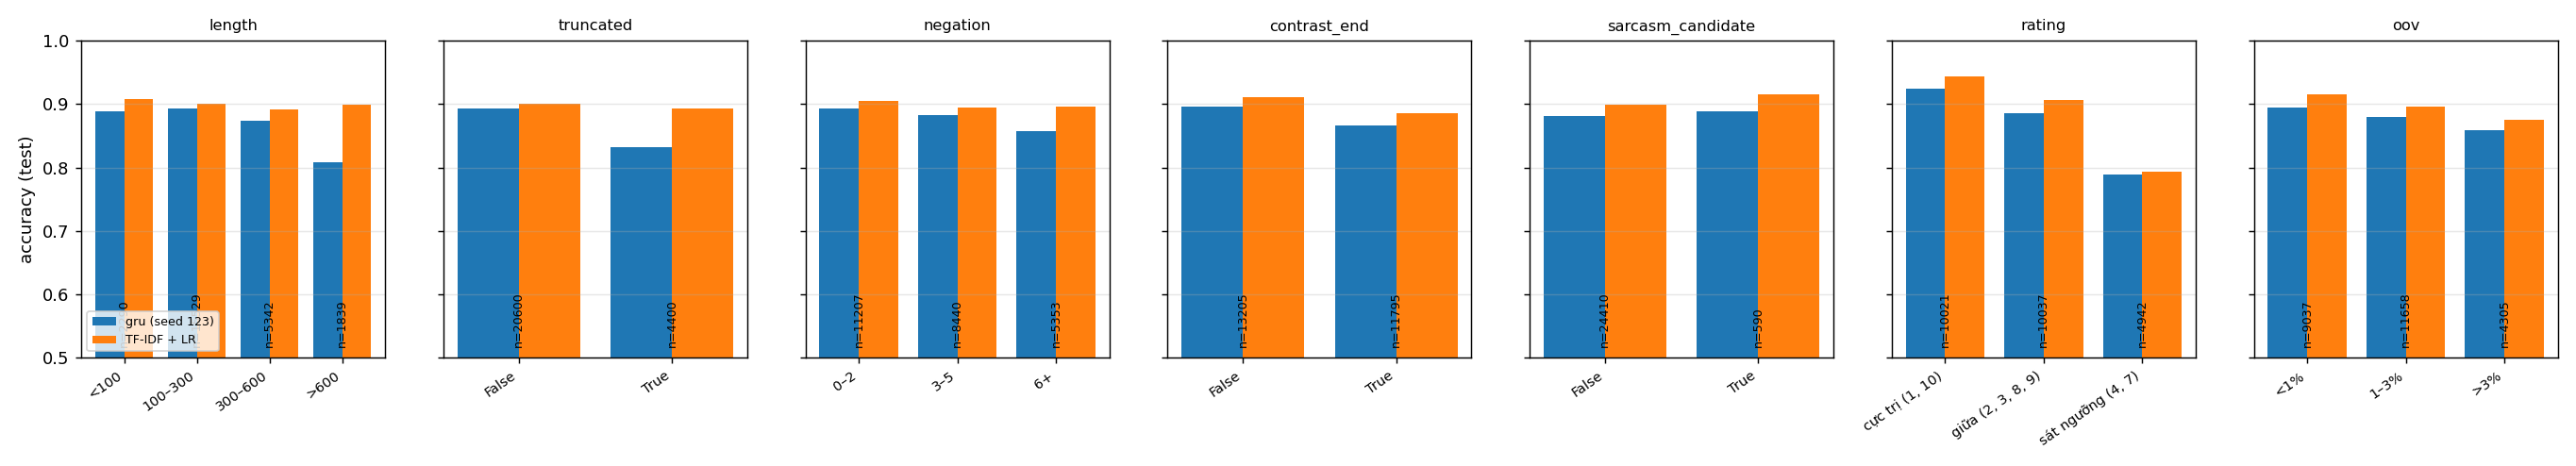

In [17]:
print("4. Accuracy theo nhóm, GRU so với baseline (đủ 25.000 review test):")
show_img(PLOTS / "error_analysis" / "acc_by_group.png", "T2", width=900)

In [18]:
# Lỗi tự tin nhất: mô hình sai nhưng xác suất xa 0,5 (lấy từ error_examples.csv)
wrong = ex.assign(confidence=lambda d: (d["prob"] - 0.5).abs()).drop_duplicates("uid").nlargest(5, "confidence")
wrong[["uid", "label", "rating", "prob"]].assign(text=wrong["text"].str[:150] + "…")

,uid,label,rating,prob,text
50,test_neg_3794,0,4,0.999828,"I went to see this 3 nights ago here in Cork, Ireland. It was the world premiere of it, in the tiny cinema in the Tr..."
30,test_neg_2370,0,4,0.999733,This film derives from a Long Running ITV sitcom by the same name.The Sitcom lasted for half a decade roughly and br...
40,test_neg_12130,0,1,0.999717,This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it a...
60,test_pos_6963,1,8,0.000422,"The lovely, yet lethal Alexandra (stunning statuesque blonde beauty Stacie Randall, who looks absolutely smashing in..."
31,test_neg_7698,0,4,0.999541,"These days, Ridley Scott is one of the top directors and producers and can command huge sums to helm movies--especia..."


### 7.2 Ba mươi câu tự viết

In [19]:
hp = pd.read_csv(RES / "error_analysis" / "handwritten_30_predictions.csv")
acc = hp.groupby("case_type")[["correct", "correct_baseline"]].mean().mul(5).astype(int).astype(str) + "/5"
film = hp[hp["case_type"] != "out_of_domain"]
print(f"30 câu tự viết (data/sample/handwritten_30.csv): GRU đúng {hp['correct'].sum()}/30, baseline {hp['correct_baseline'].sum()}/30")
print(f"Bỏ 5 câu ngoài lĩnh vực phim: GRU {film['correct'].sum()}/25 ({film['correct'].mean():.0%}), baseline {film['correct_baseline'].sum()}/25 ({film['correct_baseline'].mean():.0%})")
acc.rename(columns={"correct": "GRU", "correct_baseline": "baseline"})

30 câu tự viết (data/sample/handwritten_30.csv): GRU đúng 19/30, baseline 20/30
Bỏ 5 câu ngoài lĩnh vực phim: GRU 16/25 (64%), baseline 15/25 (60%)


,GRU,baseline
case_type,,
mixed,1/5,1/5
negation,5/5,3/5
negative,5/5,5/5
out_of_domain,3/5,5/5
positive,3/5,5/5
sarcasm,2/5,1/5


## 8. Giải thích mô hình

Dùng **occlusion**: che lần lượt từng từ rồi đo xác suất thay đổi bao nhiêu. Kiểm chứng bằng **deletion test**: bỏ k từ quan trọng nhất rồi xem xác suất có giảm nhanh hơn khi bỏ k từ ngẫu nhiên không. Kiểm thêm "đường tắt": mô hình có dựa vào tên diễn viên hoặc độ dài review không. Các hình do `src/eval/explain.py` (T3) tạo.

5. Deletion test (300 review val): che k từ quan trọng nhất so với k từ ngẫu nhiên


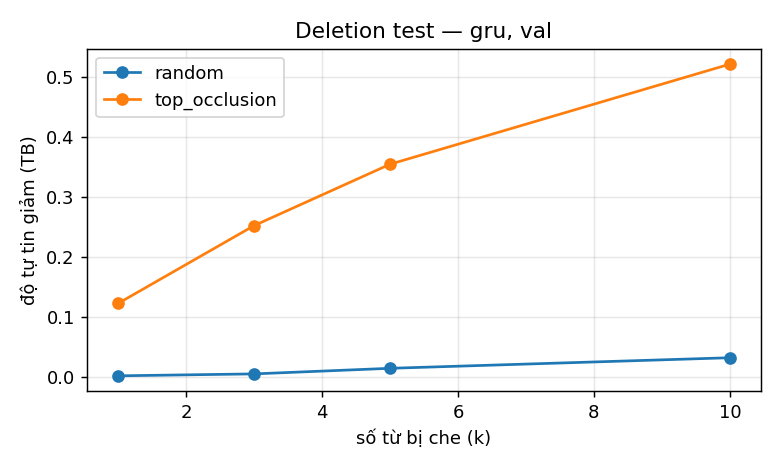

6. Occlusion, câu tự viết vừa khen vừa chê (xanh: đẩy về Positive, đỏ: đẩy về Negative):


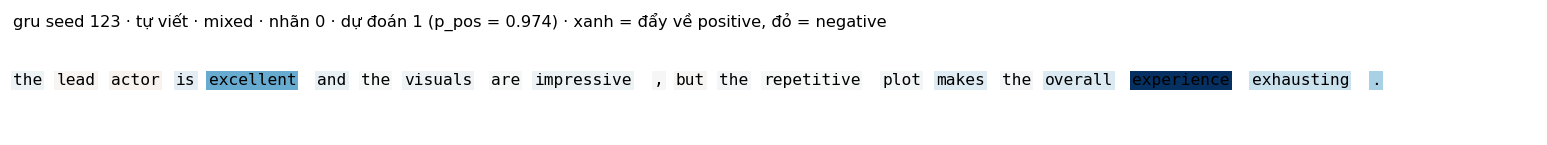

7. Occlusion, review test bị đoán sai:


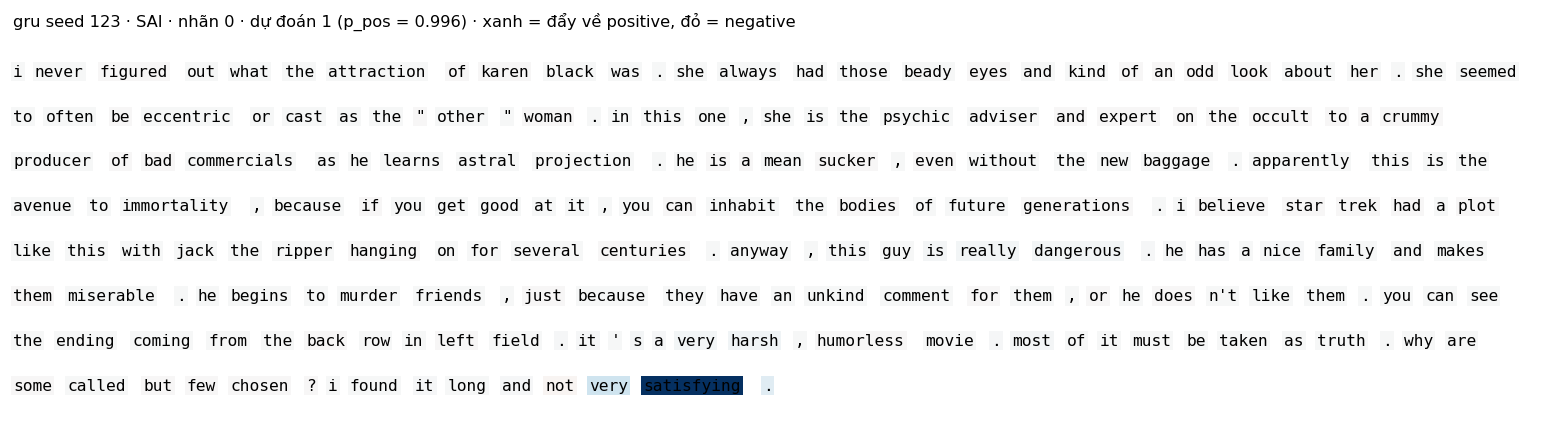

Các hình khác: experiments/plots/explain/


In [20]:
print("5. Deletion test (300 review val): che k từ quan trọng nhất so với k từ ngẫu nhiên")
show_img(PLOTS / "explain" / "deletion_test.png", "T3", width=560)
print("6. Occlusion, câu tự viết vừa khen vừa chê (xanh: đẩy về Positive, đỏ: đẩy về Negative):")
show_img(PLOTS / "explain" / "occlusion_hand_mixed_20.png", "T3", width=820)
print("7. Occlusion, review test bị đoán sai:")
show_img(PLOTS / "explain" / "occlusion_sample_wrong_test_neg_5453.png", "T3", width=820)
print("Các hình khác: experiments/plots/explain/")

In [21]:
s = read_json(RES / "explain" / "summary.json")
d = pd.DataFrame(s["deletion_test"]).pivot(index="k", columns="how", values="flip_rate")
print(f"{s['model'].upper()} seed {s['seed']}, {s['n_val_reviews']} review val. Tỉ lệ đổi nhãn khi che k từ:")
for k, r in d.iterrows():
    print(f"  k = {k:>2}: từ quan trọng nhất {r['top_occlusion']:.0%} | từ ngẫu nhiên {r['random']:.1%}")
n, L = s["shortcut_names"], s["shortcut_length"]
print(f"Tên riêng: che hết tên riêng đổi nhãn {n['names_flip_rate']:.1%}, che ngẫu nhiên cùng số từ {n['random_flip_rate']:.1%}")
print(f"Độ dài: Spearman(độ dài, xác suất khen) = {L['spearman_len_vs_prob_pos']:.3f}, p = {L['p_value_prob']:.2f}")
tt = pd.read_csv(RES / "explain" / "top_tokens_val.csv")
for side in ["positive", "negative"]:
    t = tt[tt["direction"] == side].head(8)
    print(f"Token đẩy về {side}: " + ", ".join(f"{a} ({c})" for a, c in zip(t["token"], t["count"])))

GRU seed 123, 300 review val. Tỉ lệ đổi nhãn khi che k từ:
  k =  1: từ quan trọng nhất 17% | từ ngẫu nhiên 0.7%
  k =  3: từ quan trọng nhất 30% | từ ngẫu nhiên 1.3%
  k =  5: từ quan trọng nhất 39% | từ ngẫu nhiên 3.7%
  k = 10: từ quan trọng nhất 59% | từ ngẫu nhiên 5.3%
Tên riêng: che hết tên riêng đổi nhãn 6.4%, che ngẫu nhiên cùng số từ 5.3%
Độ dài: Spearman(độ dài, xác suất khen) = -0.043, p = 0.46
Token đẩy về positive: awesome (5), 7 (12), months (4), abc (10), ultimately (4), gorgeous (5), gentle (3), fitting (4)
Token đẩy về negative: sexy (3), 4 (13), books (4), disappointment (7), costs (3), disappointing (7), poorly (8), worse (6)


## 9. Demo

Dùng hàm `predict(text) -> (label, prob)` trong `src/predict.py` (Bảo, B6). Đây cũng là hàm mà giao diện Gradio `python -m src.demo.app` gọi. Cần checkpoint `experiments/checkpoints/gru/` trên máy (không có trong repo).

In [22]:
DEMO = [
    "I expected nothing and still came away disappointed; the plot falls apart within the first twenty minutes.",
    "Not a bad film at all. The ending surprised me and I would happily watch it again.",
    "The cast is wonderful, but the script gives them nothing to do and the last act is a mess.",
] + pd.read_csv(ROOT / "data" / "sample" / "handwritten_30.csv").groupby("case_type").head(1)["text"].tolist()

from src.predict import predict  # cùng hàm mà giao diện Gradio gọi

res = pd.DataFrame([(t, *predict(t)) for t in DEMO], columns=["text", "pred", "prob khen"])
res.assign(text=res["text"].str[:90]).round(3)

,text,pred,prob khen
0,I expected nothing and still came away disappointed; the plot falls apart within the first,0,0.006
1,Not a bad film at all. The ending surprised me and I would happily watch it again.,0,0.257
2,"The cast is wonderful, but the script gives them nothing to do and the last act is a mess.",0,0.013
3,"Every scene feels carefully considered, and the lead actress delivers an emotional perform",1,0.963
4,"The plot is painfully predictable, and the characters behave in ways that make absolutely",0,0.007
5,"It is not a bad film at all; the performances are convincing, and the story has more emoti",1,0.575
6,"Wonderful, another film where every character shouts instead of having a conversation. The",0,0.272
7,"The lead actor is excellent and the visuals are impressive, but the repetitive plot makes",1,0.974
8,"The restaurant has a welcoming atmosphere, the staff are attentive, and every dish arrives",1,0.998


M5: 130 review, CPU, gồm dự đoán + tô màu: trung vị 59.9 ms, P95 96.1 ms, chậm nhất 199.4 ms → dưới 1 giây: 100%
8. Giao diện Gradio (python -m src.demo.app):


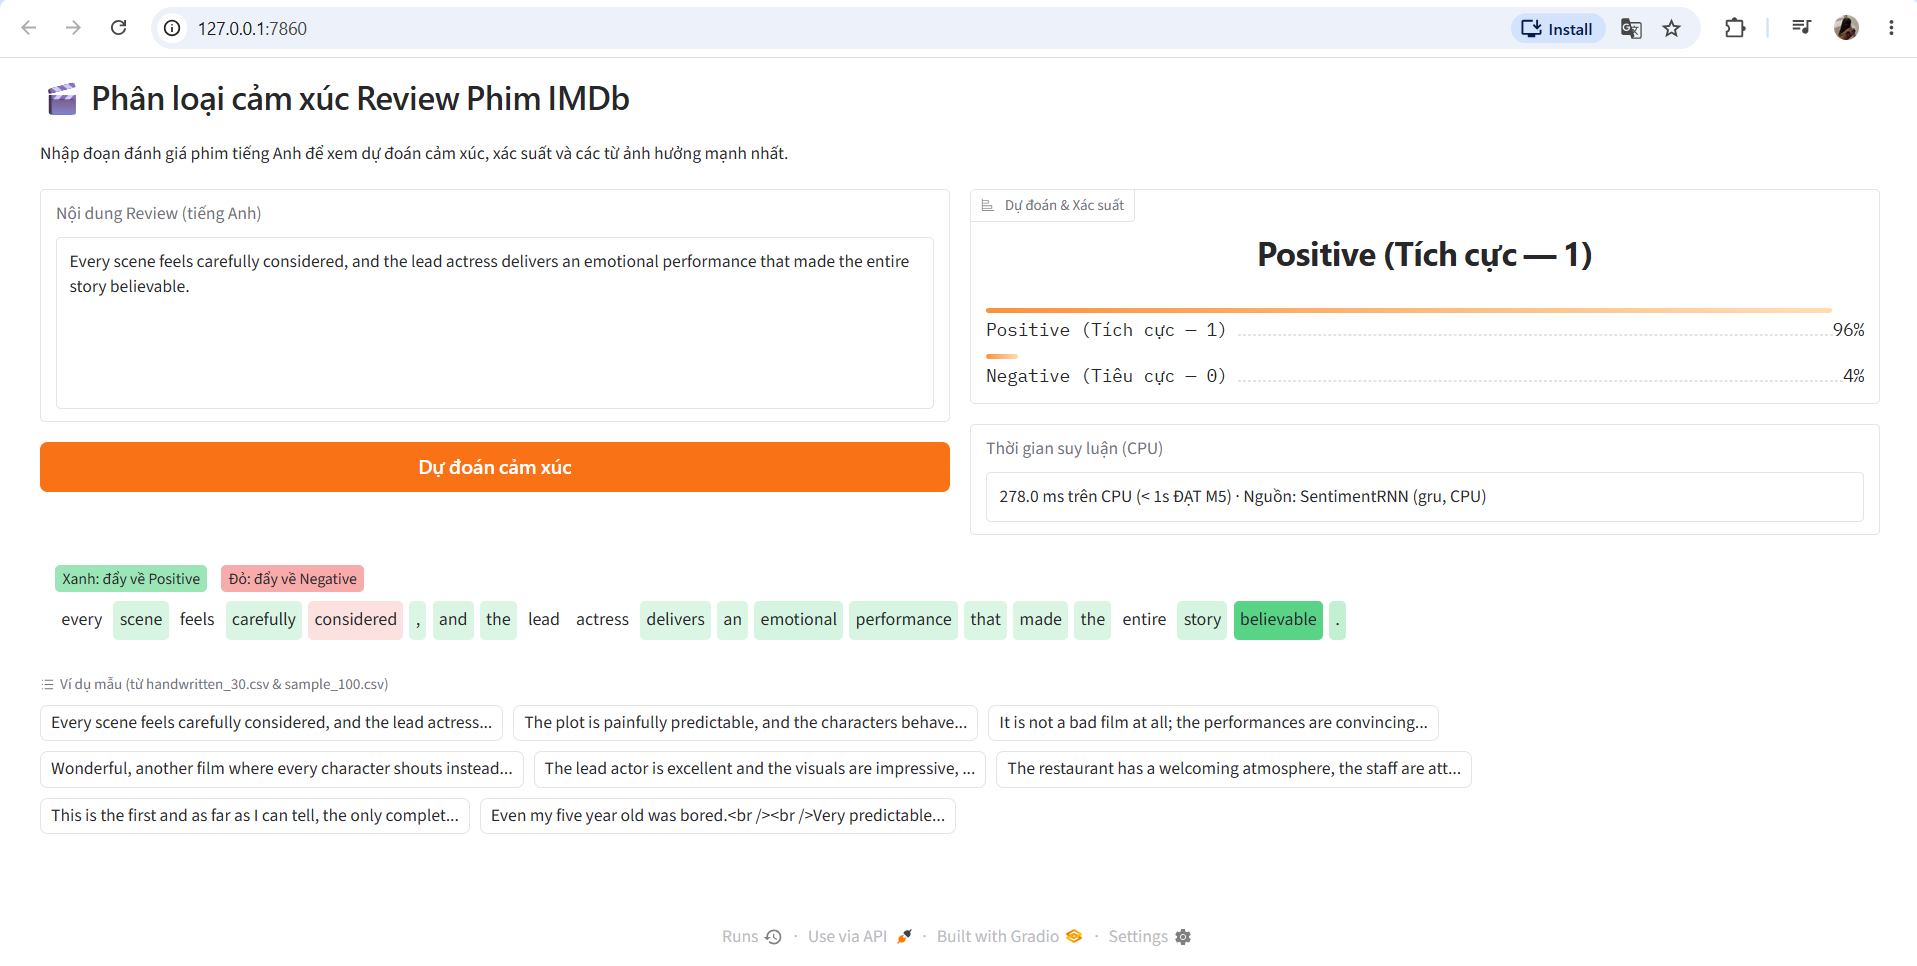

9. Câu đổi ý sau 'but' bị đoán sai:


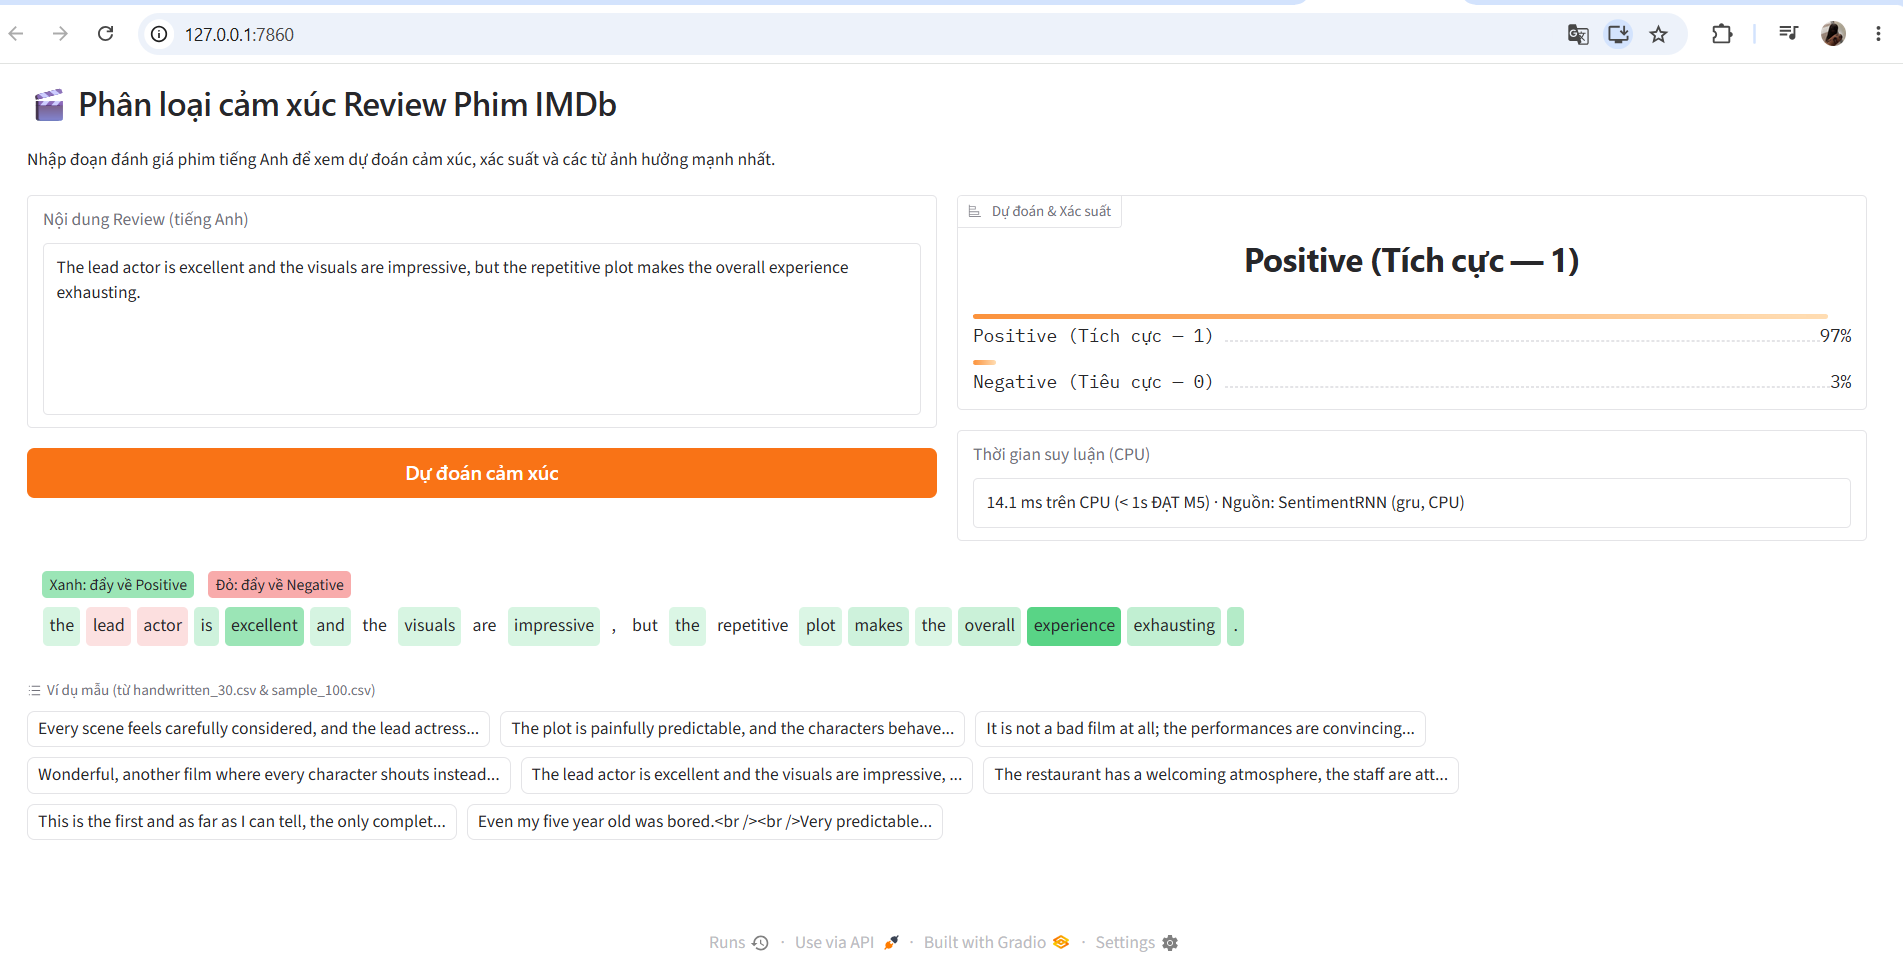

In [23]:
lat = read_json(RES / "demo" / "latency.json")
assert lat["m5_pass"]
print(f"M5: {lat['n_reviews']} review, CPU, gồm dự đoán + tô màu: trung vị {lat['ms_median']} ms, "
      f"P95 {lat['ms_p95']} ms, chậm nhất {lat['ms_max']} ms → dưới 1 giây: {lat['share_under_1s']:.0%}")
print("8. Giao diện Gradio (python -m src.demo.app):")
show_img(PLOTS / "demo" / "demo_screenshot.png", "ảnh demo", width=820)
print("9. Câu đổi ý sau 'but' bị đoán sai:")
show_img(PLOTS / "demo" / "demo_screenshot_2.png", "ảnh demo", width=820)

## 10. Giới hạn

- **Mô hình chưa hiểu cấu trúc câu:** trong 50 lỗi gán tay (lấy ngẫu nhiên trong 1.591 / 2.947 lỗi có từ đổi ý cuối bài hoặc từ mỉa mai), khen chê lẫn lộn chiếm 28%, phủ định 18%, mỉa mai 12%, đổi đối tượng (khen phim khác, nhạc phim…) 12%. Ví dụ ảnh demo thứ hai: câu đổi ý sau "but" bị đoán Positive 97%. Trên 30 câu tự viết, nhóm "vừa khen vừa chê" chỉ đúng 1/5.
- **Cắt độ dài:** với `max_len` = 400 còn 18,7% review train bị cắt; review > 600 token đúng 80,8% (baseline 89,9%). Cắt mất kết luận chỉ còn khoảng 8% lỗi — không còn là nguyên nhân chính.
- **Điểm sát ngưỡng (4, 7):** accuracy 78,9% so với 92,4% ở điểm cực trị (1, 10); baseline cũng chỉ 79,3% — nhiều review loại này tự khen chê lẫn lộn.
- **Nhiễu nhãn và đường tắt:** khoảng 6% lỗi là review có nội dung ngược với điểm người viết tự chấm. Mô hình dùng cả điểm tự ghi trong review ("7", "8" nằm trong nhóm token đẩy mạnh về positive); không dựa vào tên diễn viên (che tên riêng ảnh hưởng ngang che ngẫu nhiên).
- **Dữ liệu phân cực:** IMDb không có review điểm 5–6, nên mô hình không được kiểm trên review trung tính.
- **Test còn review trùng nội bộ:** bước loại trùng chỉ xử lý trùng giữa train và test (vd. `test_pos_12386` = `test_pos_7403`).
- **Một lần chạy, một máy:** mỗi cấu hình 3 seed trên Kaggle T4; ablation `max_len` chỉ 1 seed. Chạy lại theo README cho đúng số (M6), nhưng độ lệch giữa seed (đến ± 0,93 điểm val) lớn hơn một số khác biệt giữa mô hình.
- **Ngoài miền:** chỉ huấn luyện trên review phim tiếng Anh. Kết quả trên review sản phẩm hoặc nhà hàng chỉ mang tính tham khảo.
- **Tham chiếu:** DistilBERT (Lab 3) vẫn cao hơn. LSTM nhẹ và nhanh hơn, nhưng thua về độ chính xác.